# Bank of England gilt purchases in 2016

**Part A, Steps 1–4.** Did the 4 August announcement move yields unusually far, and did the move vary with eligibility or duration?

**Part B, Steps 5–10.** Did a purchased gilt move relative to comparable unpurchased gilts on operation day, and how much of that move reversed before the next purchase?

**Part C, Steps 11–12.** Did the whole sector move further when an operation removed more duration risk? Step 12 documents the purchase sample used in the analysis.

## Step 1. Daily yield changes

Measure how much each gilt’s yield moved in one trading day
convert its yield into basis points and subtract its yield at the preceding business close

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

out = Path("part_a_outputs")
out.mkdir(exist_ok=True)
event = pd.Timestamp("2016-08-04")
base = pd.Timestamp("2016-08-03")
sectors = ["Ineligible", "3–7", "7–15", "15+"]

def maturity_sector(years):
    labels = np.select(
        [years < 3, years < 7, years <= 15],
        sectors[:3], default=sectors[3]
    )
    return pd.Categorical(labels, categories=sectors, ordered=True)

daily = pd.read_csv("gilt_prices_daily.csv", dtype={"isin": "string"})
required = {"gilt_name", "isin", "redemption_date", "date", "clean_price",
            "yield_percent", "modified_duration"}
if missing := required.difference(daily.columns):
    raise ValueError(f"Missing columns: {sorted(missing)}")
daily["isin"] = daily["isin"].str.strip().replace("", pd.NA)
for col in ["date", "redemption_date"]:
    daily[col] = pd.to_datetime(daily[col], format="mixed", dayfirst=True)
for col in ["yield_percent", "modified_duration"]:
    daily[col] = pd.to_numeric(daily[col], errors="raise")

if daily[["isin", "date", "redemption_date"]].isna().any().any():
    raise ValueError("Missing ISIN, observation date or redemption date.")
if np.isinf(daily[["yield_percent", "modified_duration"]]).any().any():
    raise ValueError("Infinite yield or duration.")
if daily.groupby("isin")["redemption_date"].nunique().gt(1).any():
    raise ValueError("A gilt has conflicting redemption dates.")
key_counts = daily.groupby(["isin", "date"]).size()
if key_counts.gt(1).any():
    raise ValueError(f"Repeated gilt-date keys:\n{key_counts[key_counts > 1]}")

calendar = pd.DatetimeIndex(daily["date"].unique()).sort_values()
if (calendar.min(), calendar.max()) != (pd.Timestamp("2016-07-15"), pd.Timestamp("2016-12-30")):
    raise ValueError("Expected the full daily price sample from 15 July to 30 December 2016.")
if (calendar.dayofweek >= 5).any():
    raise ValueError(f"Weekend observation dates: {calendar[calendar.dayofweek >= 5].tolist()}")
day_number = pd.Series(range(1, len(calendar) + 1), index=calendar)
daily = daily.sort_values(["isin", "date"]).reset_index(drop=True)
daily["t"] = daily["date"].map(day_number)
daily["yield_bp"] = 100 * daily["yield_percent"]

by_gilt = daily.groupby("isin", sort=False)
consecutive = by_gilt["t"].diff().eq(1)
daily["change_bp"] = by_gilt["yield_bp"].diff().where(consecutive)
daily["duration_prev"] = by_gilt["modified_duration"].shift().where(consecutive)
daily["maturity_years"] = (daily["redemption_date"] - daily["date"]).dt.days / 365.25
daily["sector"] = maturity_sector(daily["maturity_years"])

assert day_number.loc["2016-07-15"] == 1 and day_number.loc["2016-08-08"] == 17
for earlier, later, distance in [("2016-08-26", "2016-08-30", 1), ("2016-08-08", "2016-08-15", 5)]:
    if earlier not in day_number or later not in day_number or day_number[later] - day_number[earlier] != distance:
        raise ValueError(f"Price calendar disagrees with the brief between {earlier} and {later}.")
assert daily.loc[daily["t"].eq(1), "change_bp"].isna().all()
assert list(maturity_sector(pd.Series([2.99, 3, 7, 15, 15.01]))) == [
    "Ineligible", "3–7", "7–15", "7–15", "15+"
]
daily.to_csv(out / "daily_changes.csv", index=False)
ordinary = daily.loc[daily["date"].between("2016-07-18", base), "change_bp"]
print(f"Median absolute daily gilt move before the announcement: {ordinary.abs().median():.2f} bp")

Median absolute daily gilt move before the announcement: 2.03 bp


## Step 2. Announcement-day moves across maturities

For each group, calculate its average gilt yield change that day. Then compare it with the standard deviation of that group’s daily average changes over the 13 preceding trading days from 18 July to 3 August.

Then ask: which gilts moved the most?

Conventional gilt yield changes on 4 August 2016 (bp). Benchmark: sector daily means, 18 July–3 August. Move in SD is unitless.


,announcement_bp,normal_sd_bp,normal_days,event_gilts,move_in_sd
sector,,,,,
Ineligible,-5.867,2.226,13,8,-2.635
3–7,-15.196,3.044,13,10,-4.993
7–15,-16.505,4.269,13,8,-3.866
15+,-15.041,4.171,13,16,-3.606


Within six months of 3 years: 2 gilts below, 1 at or above.


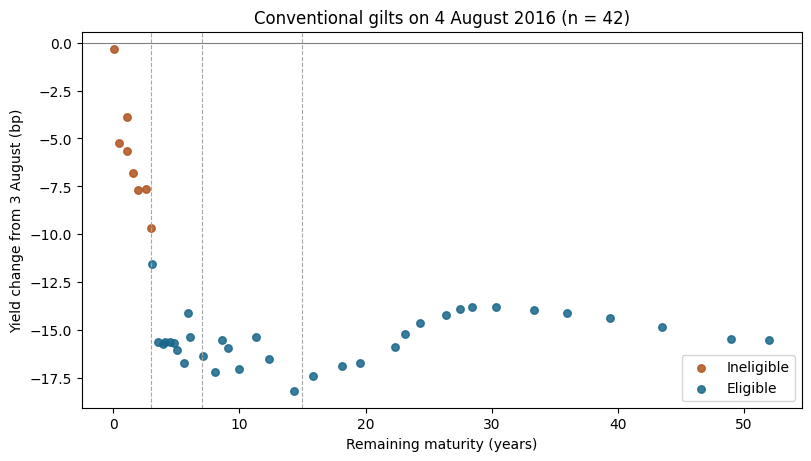

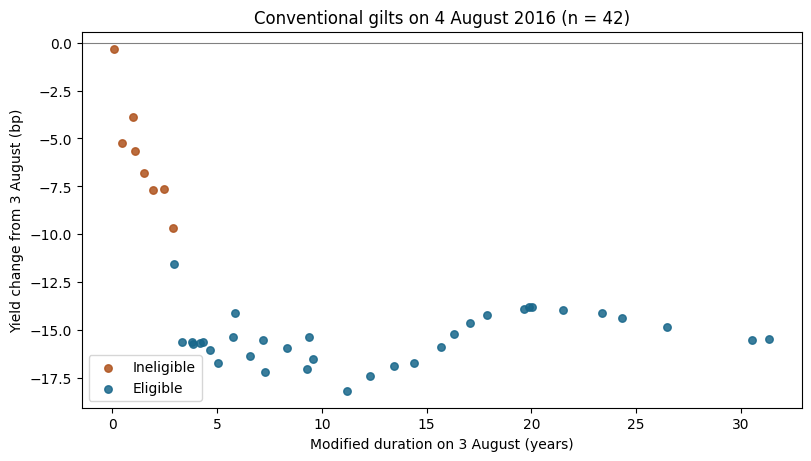

In [5]:
announcement = daily.loc[daily["date"].eq(event)].copy()
announcement.to_csv(out / "announcement_gilts.csv", index=False)

sector_means = (
    daily.groupby(["date", "sector"], observed=True)["change_bp"]
    .mean().unstack("sector").reindex(index=calendar, columns=sectors)
)
prior = sector_means.loc["2016-07-18":base]
assert len(prior) == 13

summary = pd.DataFrame({
    "announcement_bp": sector_means.loc[event],
    "normal_sd_bp": prior.std(ddof=1),
    "normal_days": prior.count(),
    "event_gilts": announcement.groupby("sector", observed=True)["change_bp"].count()
}).reindex(sectors)
summary["event_gilts"] = summary["event_gilts"].fillna(0).astype(int)
summary["move_in_sd"] = summary["announcement_bp"].div(
    summary["normal_sd_bp"].where(summary["normal_sd_bp"] > 0)
)
summary.to_csv(out / "announcement_by_sector.csv")
print(
    "Conventional gilt yield changes on 4 August 2016 (bp). "
    "Benchmark: sector daily means, 18 July–3 August. Move in SD is unitless."
)
display(summary.round(3))
near = announcement.dropna(subset=["change_bp"]).query("2.5 <= maturity_years <= 3.5")
below = near["maturity_years"].lt(3).sum()
print(f"Within six months of 3 years: {below} gilts below, {len(near) - below} at or above.")

for x, xlabel in [("maturity_years", "Remaining maturity (years)"),
                  ("duration_prev", "Modified duration on 3 August (years)")]:
    points = announcement.dropna(subset=[x, "change_bp"])
    fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
    eligible = points["sector"].ne("Ineligible")
    for label, mask, colour in [("Ineligible", ~eligible, "#ae521c"),
                                ("Eligible", eligible, "#17668a")]:
        ax.scatter(points.loc[mask, x], points.loc[mask, "change_bp"],
                   label=label, color=colour, s=29, alpha=0.85)
    if x == "maturity_years":
        for boundary in [3, 7, 15]:
            ax.axvline(boundary, color="0.65", ls="--", lw=0.8)
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set(xlabel=xlabel, ylabel="Yield change from 3 August (bp)",
           title=f"Conventional gilts on 4 August 2016 (n = {len(points)})")
    ax.legend()
    fig.savefig(out / f"announcement_{x}.png", dpi=300)
    plt.show()

## Step 3. Eligible versus ineligible gilts

The two rows report the required one-day and two-day comparisons. All other valid start dates enter the two-day benchmark, including 3 and 5 August. An unusually negative gap indicates that eligible yields fell further relative to ineligible yields than usual. The Bank Rate cut could move shorter yields through expectations of near-term policy. The Term Funding Scheme could change those expectations by strengthening pass-through. Corporate bond purchases could shift demand across maturities as investors reinvest. A shared announcement date makes it difficult to isolate the gilt programme.

In [6]:
eligible = daily["sector"].ne("Ineligible").rename("eligible")
group_means = (
    daily.groupby(["date", eligible])["change_bp"].mean()
    .unstack("eligible").reindex(index=calendar, columns=[False, True])
)
gaps = group_means.set_axis(["ineligible_bp", "eligible_bp"], axis=1)
gaps["gap_bp"] = gaps["eligible_bp"] - gaps["ineligible_bp"]
gaps["two_day_bp"] = gaps["gap_bp"] + gaps["gap_bp"].shift(-1)

def compare_window(values):
    actual = values.loc[event]
    other = values.drop(index=event).dropna()
    mean, sd = other.mean(), other.std(ddof=1)
    can_rank = pd.notna(actual) and not other.empty
    return pd.Series({
        "event_bp": actual,
        "other_mean_bp": mean,
        "other_sd_bp": sd,
        "z": (actual - mean) / sd if can_rank and sd > 0 else np.nan,
        "at_least_as_negative": int(other.le(actual).sum()) if can_rank else np.nan,
        "other_windows": len(other)
    })

assert day_number.loc["2016-08-05"] == day_number.loc[event] + 1
announcement_tests = pd.DataFrame({
    "4 August": compare_window(gaps["gap_bp"]),
    "4–5 August": compare_window(gaps["two_day_bp"])
}).T
counts = ["at_least_as_negative", "other_windows"]
announcement_tests[counts] = announcement_tests[counts].astype("Int64")
gaps.to_csv(out / "daily_eligibility_gaps.csv", index_label="date")
announcement_tests.to_csv(out / "announcement_tests.csv", index_label="window")
print(
    "Eligible minus ineligible gilt yield changes (bp), 15 July–30 December 2016. "
    "Each event is compared with the other valid windows of the same length; z is unitless."
)
display(announcement_tests.round(3))

Eligible minus ineligible gilt yield changes (bp), 15 July–30 December 2016. Each event is compared with the other valid windows of the same length; z is unitless.


,event_bp,other_mean_bp,other_sd_bp,z,at_least_as_negative,other_windows
4 August,-9.564,0.361,2.902,-3.421,0,116
4–5 August,-10.686,0.675,4.472,-2.541,1,115


## Step 4. The path around the announcement

Compare the period before the announcement with the move on 4 August and its continuation or reversal on 5 August. From 8 August, actual purchases can also affect the paths. The CSV reports contributing gilts separately for each point.

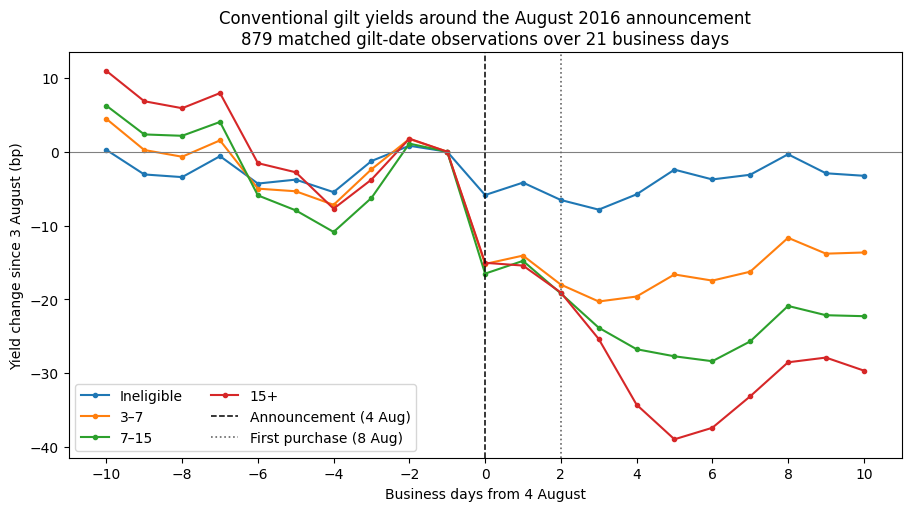

In [7]:
event_t = day_number.loc[event]
window = daily.loc[daily["t"].between(event_t - 10, event_t + 10)].copy()
window["tau"] = window["t"] - event_t
window["event_sector"] = maturity_sector(
    (window["redemption_date"] - event).dt.days / 365.25
)

base_yield = daily.loc[daily["date"].eq(base)].set_index("isin")["yield_bp"]
assert base_yield.index.is_unique
window["from_base_bp"] = window["yield_bp"] - window["isin"].map(base_yield)

path = window.groupby(["tau", "event_sector"], observed=False)["from_base_bp"].agg(
    mean_bp="mean", n_gilts="count"
)
curves = path["mean_bp"].unstack().reindex(columns=sectors)

assert day_number.loc["2016-08-08"] - event_t == 2
assert set(curves.index) == set(range(-10, 11))
assert np.allclose(curves.loc[-1].dropna(), 0)
np.testing.assert_allclose(curves.loc[0], summary["announcement_bp"], equal_nan=True)
path.to_csv(out / "announcement_path.csv")

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
curves.plot(ax=ax, marker="o", markersize=3)
ax.axhline(0, color="0.5", lw=0.8)
ax.axvline(0, color="black", ls="--", lw=1.1, label="Announcement (4 Aug)")
ax.axvline(2, color="0.4", ls=":", lw=1.2, label="First purchase (8 Aug)")
ax.set(xlabel="Business days from 4 August", ylabel="Yield change since 3 August (bp)",
       title=("Conventional gilt yields around the August 2016 announcement\n"
              f"{int(path['n_gilts'].sum()):,} matched gilt-date observations over 21 business days"),
       xticks=range(-10, 11, 2))
ax.legend(ncol=2)
fig.savefig(out / "announcement_path.png", dpi=300)
plt.show()

## Step 5. Every eligible gilt on every operation date

Use the prior trading day's observed clean price to determine inclusion and the operation date to calculate maturity. The table shows the eligible universe and purchase count for each operation.

Each output row is one eligible ISIN on one operation date. The purchase indicator is one only when that exact pair appears in the purchase file. Output: `operation_universe.csv`.

In [8]:
b_out = Path("part_b_outputs")
b_out.mkdir(exist_ok=True)
keys = ["operation_date", "isin"]
proceeds_col = "total_allocation_proceeds_mn"
purchases = pd.read_csv("purchase_operations.csv", dtype={"isin": "string", proceeds_col: "string"})
required = {*keys, "bond", "total_allocation_nominal_mn", "total_allocation_proceeds_mn",
            "amount_outstanding_mn", "mod_duration_prev"}
if missing := required.difference(purchases.columns):
    raise ValueError(f"Missing purchase columns: {sorted(missing)}")
purchases["isin"] = purchases["isin"].str.strip().replace("", pd.NA)
purchases["operation_date"] = pd.to_datetime(purchases["operation_date"], format="mixed", dayfirst=True)
if purchases[keys].isna().any().any() or purchases.duplicated(keys).any():
    raise ValueError("Missing or repeated (operation_date, isin) in the purchase file.")

proceeds_text = purchases.set_index(keys)[proceeds_col].astype(object).rename("proceeds_text")

for col in ["total_allocation_nominal_mn", "amount_outstanding_mn",
            "total_allocation_proceeds_mn", "mod_duration_prev"]:
    purchases[col] = pd.to_numeric(purchases[col], errors="raise").astype(float)
    if np.isinf(purchases[col]).any():
        raise ValueError(f"Infinite values in {col}.")
if not purchases["total_allocation_nominal_mn"].gt(0).all():
    raise ValueError("The purchase file must contain positive allocations.")

ops = purchases[["operation_date"]].drop_duplicates().sort_values("operation_date").copy()
ops["t0"] = ops["operation_date"].map(day_number)
if len(ops) != 54 or ops["t0"].isna().any():
    raise ValueError("Expected 54 purchase dates present in the gilt trading calendar.")
date_by_t = pd.Series(calendar, index=day_number.values)
ops["prev_business_date"] = (ops["t0"] - 1).map(date_by_t)
assert ops.iloc[0]["operation_date"] == pd.Timestamp("2016-08-08")
assert ops.iloc[0]["t0"] == 17 and ops.iloc[0]["prev_business_date"] == pd.Timestamp("2016-08-05")

assert ops.iloc[-1]["operation_date"] == pd.Timestamp("2016-12-14")
if "prev_business_date" in purchases:
    reported = pd.to_datetime(purchases["prev_business_date"], format="mixed", dayfirst=True)
    expected = purchases["operation_date"].map(ops.set_index("operation_date")["prev_business_date"])
    if not reported.eq(expected).all():
        raise ValueError("A purchase has a prior business date inconsistent with the price calendar.")

daily["clean_price"] = pd.to_numeric(daily["clean_price"], errors="raise")
if np.isinf(daily["clean_price"]).any():
    raise ValueError("Infinite clean price in the daily file.")
quotes = daily.set_index(["isin", "date"])[["yield_bp", "clean_price"]]
gilts = daily[["isin", "redemption_date"]].drop_duplicates()
assert gilts["isin"].is_unique and quotes.index.is_unique
universe = ops.merge(gilts, how="cross")
assert len(universe) == len(ops) * len(gilts)
prior_keys = pd.MultiIndex.from_arrays([universe["isin"], universe["prev_business_date"]])
universe = universe.loc[quotes["clean_price"].reindex(prior_keys).notna().to_numpy()].copy()
universe["maturity_years"] = (universe["redemption_date"] - universe["operation_date"]).dt.days / 365.25
universe["sector"] = maturity_sector(universe["maturity_years"])
universe = universe.loc[universe["sector"].ne("Ineligible")].copy()
bought = pd.MultiIndex.from_frame(purchases[keys])
universe["purchased"] = pd.MultiIndex.from_frame(universe[keys]).isin(bought).astype(int)
omitted = bought.difference(pd.MultiIndex.from_frame(universe[keys]))
if len(omitted):
    raise ValueError(f"Purchases absent from the eligible, previously priced universe: {omitted.tolist()}")
assert not universe.duplicated(keys).any() and universe["purchased"].sum() == len(purchases)
universe.to_csv(b_out / "operation_universe.csv", index=False)
display(universe.groupby("operation_date")["purchased"].agg(eligible_gilts="size", purchased_gilts="sum"))


,eligible_gilts,purchased_gilts
operation_date,,
2016-08-08,34,4
2016-08-09,34,14
2016-08-10,34,6
2016-08-15,34,6
2016-08-16,34,10
2016-08-17,34,6
2016-08-22,34,5
2016-08-23,34,14
2016-08-24,34,6


**Prior-close data check.** The purchase file supplies the modified duration used in Steps 10–12. Compare it with the daily quote for the same ISIN on the preceding business date. The table also checks prior yield and clean price when the purchase file supplies them. It reports the number of comparable pairs, missing values and the largest absolute difference in the stated units. Source rounding can produce small differences. The estimates use the purchase-file fields specified in the brief.

In [9]:
previous = purchases["operation_date"].map(ops.set_index("operation_date")["prev_business_date"])
prior_index = pd.MultiIndex.from_arrays([purchases["isin"], previous])
quote_fields = daily.set_index(["isin", "date"])[["modified_duration", "yield_percent", "clean_price"]]
previous_quotes = quote_fields.reindex(prior_index).set_axis(purchases.index)
rows = []
for field, column, unit, scale in [
    ("mod_duration_prev", "modified_duration", "years", 1),
    ("yield_percent_prev", "yield_percent", "bp", 100),
    ("clean_price_prev", "clean_price", "£ per £100 nominal", 1)
]:
    if field in purchases:
        supplied = pd.to_numeric(purchases[field], errors="raise")
        quoted = previous_quotes[column]
        difference = (supplied - quoted).abs() * scale
        rows.append({"field": field, "unit": unit, "comparable": difference.count(),
                     "missing_in_purchase_file": supplied.isna().sum(),
                     "missing_in_daily_file": quoted.isna().sum(),
                     "max_absolute_difference": difference.max()})
prior_quote_check = pd.DataFrame(rows).set_index("field")
prior_quote_check.to_csv(b_out / "prior_quote_check.csv")
display(prior_quote_check)

,unit,comparable,missing_in_purchase_file,missing_in_daily_file,max_absolute_difference
field,,,,,
mod_duration_prev,years,361,0,0,0.0
yield_percent_prev,bp,361,0,0,0.0
clean_price_prev,£ per £100 nominal,361,0,0,0.0


## Step 6. Match purchased gilts to comparison gilts

Choose fixed same-sector neighbours on either side of the purchased maturity. When several candidates tie on one side, the lowest ISIN wins. The strict shorter/longer rule excludes candidates with the same maturity as the target. Unmatched purchases retain a row with missing weights.

Each row is one purchase, including purchases with no match. Outputs: `comparison_gilts.csv` and `match_counts_by_sector.csv`.

In [10]:
def match_gilt(row, candidates):
    years = row.maturity_years
    shorter = candidates.loc[candidates["maturity_years"] < years]
    longer = candidates.loc[candidates["maturity_years"] > years]
    lo = shorter.loc[shorter["maturity_years"].idxmax()] if len(shorter) else None
    hi = longer.loc[longer["maturity_years"].idxmin()] if len(longer) else None
    if lo is not None and hi is not None:
        w_lo = (hi.maturity_years - years) / (hi.maturity_years - lo.maturity_years)
        kind, w_hi = "bracketed", 1 - w_lo
    elif lo is not None or hi is not None:
        kind, w_lo, w_hi = "nearest-neighbour", float(lo is not None), float(hi is not None)
    else:
        kind, w_lo, w_hi = "unmatched", np.nan, np.nan
    return (row.operation_date, row.isin, row.sector, years, kind,
            lo["isin"] if lo is not None else pd.NA, hi["isin"] if hi is not None else pd.NA,
            lo.maturity_years if lo is not None else np.nan,
            hi.maturity_years if hi is not None else np.nan, w_lo, w_hi)

records = []
for _, group in universe.groupby(["operation_date", "sector"], observed=True):
    candidates = group.loc[group["purchased"].eq(0)].sort_values("isin")
    for row in group.loc[group["purchased"].eq(1)].itertuples():
        records.append(match_gilt(row, candidates))

matches = pd.DataFrame(records, columns=[
    *keys, "sector", "maturity_years", "match_type", "isin_L", "isin_U",
    "maturity_L", "maturity_U", "w_L", "w_U"
])
assert len(matches) == len(purchases) and not matches.duplicated(keys).any()
weights = matches.loc[matches["match_type"].ne("unmatched"), ["w_L", "w_U"]]
assert weights.ge(0).all().all() and weights.le(1).all().all()
np.testing.assert_allclose(weights.sum(axis=1), 1)
br = matches.loc[matches["match_type"].eq("bracketed")]
np.testing.assert_allclose(br["w_L"] * br["maturity_L"] + br["w_U"] * br["maturity_U"],
                           br["maturity_years"])
match_counts = pd.crosstab(matches["sector"], matches["match_type"]).reindex(
    index=sectors[1:], columns=["bracketed", "nearest-neighbour", "unmatched"], fill_value=0
)
matches.to_csv(b_out / "comparison_gilts.csv", index=False)
match_counts.to_csv(b_out / "match_counts_by_sector.csv")
display(match_counts)


match_type,bracketed,nearest-neighbour,unmatched
sector,,,
3–7,55,52,0
7–15,22,52,0
15+,102,62,16


## Step 7. Construct the event-time panel

Each purchased gilt has 16 rows, including unmatched purchases for tracking exclusions. Yield changes are in basis points. Clean-price changes are in pounds per £100 nominal. A missing quote on a positive-weight comparison leg leaves that outcome missing. The completed panel is saved after Step 8.

AY and AP each subtract the synthetic comparison’s change from the purchased gilt’s change since day −1. A missing baseline leaves that outcome unavailable for the window.

In [11]:
horizons = pd.DataFrame({"h": range(-5, 11)})
event_dates = ops[["operation_date", "t0"]].merge(horizons, how="cross")
event_dates["date"] = (event_dates["t0"] + event_dates["h"]).map(date_by_t)
if event_dates["date"].isna().any():
    raise ValueError("At least one event window extends outside the daily price file.")
panel = matches.merge(event_dates, on="operation_date").sort_values([*keys, "h"])
assert not panel.duplicated([*keys, "h"]).any() and len(panel) == 16 * len(matches)

for code, suffix in [("isin", ""), ("isin_L", "_L"), ("isin_U", "_U")]:
    quote_keys = pd.MultiIndex.from_arrays([panel[code], panel["date"]])
    panel[["yield_bp" + suffix, "clean_price" + suffix]] = quotes.reindex(quote_keys).to_numpy()

for measure, abnormal in [("yield_bp", "AY"), ("clean_price", "AP")]:
    lower = (panel["w_L"] * panel[measure + "_L"]).mask(panel["w_L"].eq(0), 0)
    upper = (panel["w_U"] * panel[measure + "_U"]).mask(panel["w_U"].eq(0), 0)
    panel[measure + "_C"] = lower + upper
    spread = panel[measure] - panel[measure + "_C"]
    baseline = spread.loc[panel["h"].eq(-1)].copy()
    baseline.index = pd.MultiIndex.from_frame(panel.loc[panel["h"].eq(-1), keys])
    panel[abnormal] = spread - baseline.reindex(pd.MultiIndex.from_frame(panel[keys])).to_numpy()
    assert panel.loc[panel["h"].eq(-1), abnormal].dropna().eq(0).all()
assert panel.loc[panel["match_type"].eq("unmatched"), ["AY", "AP"]].isna().all().all()


## Step 8. Flag overlapping operations

An overlap begins on the first later purchase date for the gilt or either fixed comparison. The share at each positive horizon uses all purchase rows in the panel, including those with missing outcomes.

Outputs: `event_time_panel.csv` and `contamination_by_horizon.csv`. Step 9 uses only nonmissing outcomes and reports its own contributing counts.

In [12]:
first_overlap = pd.Series(pd.NaT, index=matches.index, dtype="datetime64[ns]")
for operation_date, group in matches.groupby("operation_date"):
    later = purchases.loc[purchases["operation_date"].gt(operation_date)]
    next_buy = later.groupby("isin")["operation_date"].min()
    dates = pd.concat([group[col].map(next_buy) for col in ["isin", "isin_L", "isin_U"]], axis=1)
    first_overlap.loc[group.index] = dates.min(axis=1)

overlaps = matches[keys].assign(first_overlap=first_overlap).set_index(keys)["first_overlap"]
first_date = overlaps.reindex(pd.MultiIndex.from_frame(panel[keys])).to_numpy()
panel["contaminated"] = (panel["h"].gt(0) & panel["date"].ge(first_date)).astype(int)
assert panel.loc[panel["h"].le(0), "contaminated"].eq(0).all()
assert panel.groupby(keys)["contaminated"].diff().dropna().ge(0).all()
contamination = panel.loc[panel["h"].gt(0)].groupby("h")["contaminated"].agg(
    rows="size", contaminated_rows="sum", share="mean"
)
panel.to_csv(b_out / "event_time_panel.csv", index=False)
contamination.to_csv(b_out / "contamination_by_horizon.csv")
display(contamination)


,rows,contaminated_rows,share
h,,,
1,361,0,0.000000
2,361,0,0.000000
3,361,1,0.002770
4,361,21,0.058172
5,361,269,0.745152
6,361,271,0.750693
7,361,271,0.750693
8,361,271,0.750693
9,361,275,0.761773


## Step 9. Estimate the operation-day effect and reversal

The figure and table give equal weight to operations. Confidence limits use the number of contributing operations at each horizon. Examine the five pre-operation points before interpreting the operation-day move. The purchase-level tests require all four pre-operation changes. The reversal additionally requires an uncontaminated observation at day four.

The operation-day estimate subtracts the mean of the four pre-operation daily changes from the day-zero daily change. The day-four reversal subtracts four days of that drift from the change between days zero and four. Outputs: `event_study.csv`, `operation_event_study.png`, `purchase_level_effects.csv` and `operation_day_and_reversal.csv`.

,sample,h,mean_bp,se_bp,operations,purchases,lower_95_bp,upper_95_bp
0,All,-5,-0.154,0.093,53,345,-0.340,0.033
1,All,-4,-0.152,0.078,53,345,-0.309,0.004
2,All,-3,-0.098,0.058,53,345,-0.215,0.019
3,All,-2,-0.059,0.041,53,345,-0.141,0.024
4,All,-1,0.000,0.000,53,345,0.000,0.000
5,All,0,0.071,0.033,53,345,0.005,0.137
6,All,1,0.107,0.058,53,345,-0.010,0.223
7,All,2,0.193,0.065,53,345,0.062,0.324
8,All,3,0.248,0.069,53,345,0.110,0.386
9,All,4,0.301,0.076,53,345,0.148,0.453


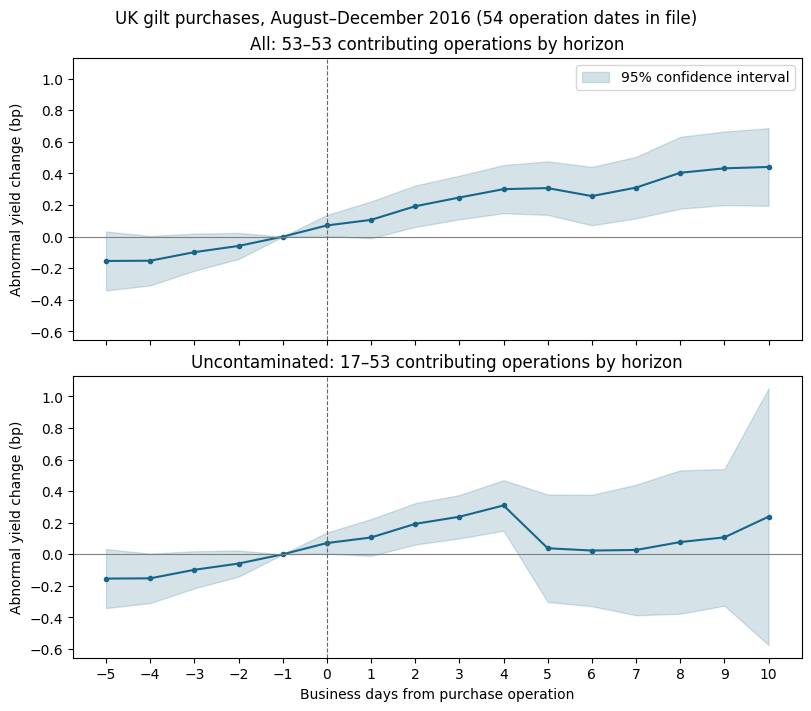

,mean_bp,se_bp,operations,purchases,lower_95_bp,upper_95_bp,t_stat
Operation day,0.033,0.038,53,345,-0.044,0.110,0.851
Four-day reversal,0.088,0.124,52,324,-0.162,0.337,0.704


In [13]:
from scipy.stats import t as student_t

def operation_summary(values):
    valid = values.dropna()
    means = valid.groupby(level="operation_date").mean()
    n = len(means)
    estimate = means.mean()
    se = means.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan
    margin = student_t.ppf(0.975, n - 1) * se if n > 1 else np.nan
    return {"mean_bp": estimate, "se_bp": se, "operations": n, "purchases": len(valid),
            "lower_95_bp": estimate - margin, "upper_95_bp": estimate + margin}

horizons = range(-5, 11)
assert not panel.duplicated(keys + ["h"]).any()
event_data = panel.set_index(keys)
samples = {"All": event_data, "Uncontaminated": event_data.loc[event_data["contaminated"].eq(0)]}

rows = []
for sample, data in samples.items():
    for h in horizons:
        values = data.loc[data["h"].eq(h), "AY"]
        rows.append({"sample": sample, "h": h, **operation_summary(values)})
event_study = pd.DataFrame(rows)
event_study.to_csv(b_out / "event_study.csv", index=False)
display(event_study.round(3))

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True, sharey=True, constrained_layout=True)
for ax, sample in zip(axes, samples):
    curve = event_study.loc[event_study["sample"].eq(sample)]
    ax.fill_between(curve["h"], curve["lower_95_bp"], curve["upper_95_bp"],
                    color="#17668a", alpha=0.18, label="95% confidence interval")
    ax.plot(curve["h"], curve["mean_bp"], color="#17668a", marker="o", ms=3)
    ax.axhline(0, color="0.5", lw=0.8)
    ax.axvline(0, color="0.4", ls="--", lw=0.8)
    ax.set(ylabel="Abnormal yield change (bp)",
           title=f"{sample}: {curve.operations.min()}–{curve.operations.max()} contributing operations by horizon")
axes[0].legend()
axes[1].set(xlabel="Business days from purchase operation", xticks=range(-5, 11))
fig.suptitle(f"UK gilt purchases, August–December 2016 ({panel['operation_date'].nunique()} operation dates in file)")
fig.savefig(b_out / "operation_event_study.png", dpi=300)
plt.show()

ay = panel.pivot(index=keys, columns="h", values="AY").reindex(columns=horizons)
daily_ay = ay.diff(axis=1)
pre_drift = daily_ay.loc[:, -4:-1].mean(axis=1, skipna=False)
clean4 = event_data.loc[event_data["h"].eq(4), "contaminated"].eq(0)
effects = pd.DataFrame({
    "pre_drift_bp_per_day": pre_drift,
    "operation_day_bp": daily_ay[0] - pre_drift,
    "day_4_reversal_bp": (ay[4] - ay[0] - 4 * pre_drift).where(clean4)
})
effects.to_csv(b_out / "purchase_level_effects.csv")

operation_tests = pd.DataFrame({
    "Operation day": operation_summary(effects["operation_day_bp"]),
    "Four-day reversal": operation_summary(effects["day_4_reversal_bp"])
}).T
operation_tests[["operations", "purchases"]] = operation_tests[["operations", "purchases"]].astype(int)
operation_tests["t_stat"] = operation_tests["mean_bp"].div(operation_tests["se_bp"].where(operation_tests["se_bp"] > 0))
operation_tests.to_csv(b_out / "operation_day_and_reversal.csv", index_label="test")
display(operation_tests.round(3))


**Clean-price robustness check.** Repeat the operation-day and clean day-four reversal tests in pounds per £100 nominal. For each test, use only purchases with both a yield and a price effect. This keeps changes in sample composition from explaining a difference between the two estimates. A relative yield fall and a relative price rise point in the same economic direction. The paired results are saved in `common_sample_price_robustness.csv`.

In [14]:
ap = panel.pivot(index=keys, columns="h", values="AP").reindex(columns=horizons)
daily_ap = ap.diff(axis=1)
price_drift = daily_ap.loc[:, -4:-1].mean(axis=1, skipna=False)
price_changes = {
    "Operation day": daily_ap[0] - price_drift,
    "Four-day reversal": (ap[4] - ap[0] - 4 * price_drift).where(clean4)
}

rows = []
for column, test in [("operation_day_bp", "Operation day"), ("day_4_reversal_bp", "Four-day reversal")]:
    paired = pd.DataFrame({"Yield": effects[column], "Clean price": price_changes[test]}).dropna()
    for outcome, unit in [("Yield", "bp"), ("Clean price", "£ per £100 nominal")]:
        effect_stats = operation_summary(paired[outcome])
        rows.append({"test": test, "outcome": outcome, "unit": unit, **effect_stats})

price_robustness = pd.DataFrame(rows).rename(columns={
    "mean_bp": "estimate", "se_bp": "se", "lower_95_bp": "lower_95", "upper_95_bp": "upper_95"
})
price_robustness["t_stat"] = price_robustness["estimate"].div(price_robustness["se"].where(price_robustness["se"] > 0))
price_robustness.to_csv(b_out / "common_sample_price_robustness.csv", index=False)
print("Matched yield and clean-price effects, UK gilt purchases, August–December 2016")
display(price_robustness.round(4))

Matched yield and clean-price effects, UK gilt purchases, August–December 2016


,test,outcome,unit,estimate,se,operations,purchases,lower_95,upper_95,t_stat
0,Operation day,Yield,bp,0.0327,0.0384,53,345,-0.0444,0.1098,0.8512
1,Operation day,Clean price,£ per £100 nominal,0.0030,0.0181,53,345,-0.0334,0.0394,0.1647
2,Four-day reversal,Yield,bp,0.0876,0.1244,52,324,-0.1622,0.3373,0.7039
3,Four-day reversal,Clean price,£ per £100 nominal,-0.0212,0.0643,52,324,-0.1502,0.1079,-0.3293


## Step 10. Estimate local-pressure regressions

Each coefficient is in basis points. The reference categories are the 3–7-year sector and August. The interaction models also report the purchase-size slope for a smaller issue or a more volatile market, evaluated one standard deviation above the mean of the relevant measure. Standard errors are clustered by operation date with the conventional finite-sample correction.

The specifications are (1) day-zero AY on relative purchase size, (2) the same model with issue illiquidity and its interaction with purchase size, (3) the same extension using volatility, and (4) the baseline using uncontaminated day-four AY and newly standardised purchase size. Volatility uses the preceding 20 observed market days and requires 10 valid changes. The day-zero model uses raw AY(0); the separately drift-adjusted operation-day effect belongs to Step 9. Outputs: `regression_data.csv` and `local_pressure_regressions.csv`.

A missing sector or a constant regressor can leave a coefficient unidentified. The regression table marks those coefficients as unavailable and retains the estimates the sample supports. A single operation cannot supply a clustered standard error.

In [15]:
market_change = daily.groupby("t", sort=True)["change_bp"].median()
volatility = market_change.rolling(20, min_periods=10).std(ddof=1).shift(1)
operation_vol = ops[["operation_date", "t0"]].copy()
operation_vol["volatility"] = operation_vol["t0"].map(volatility)

pressure = purchases.merge(matches[keys + ["sector"]], on=keys, how="left", validate="1:1")
pressure = pressure.merge(operation_vol[["operation_date", "volatility"]],
                          on="operation_date", how="left", validate="m:1")
for h in [0, 4]:
    fields = ["AY", "contaminated"] if h == 4 else ["AY"]
    outcome = panel.loc[panel["h"].eq(h), keys + fields].rename(
        columns={"AY": f"AY{h}", "contaminated": "contaminated4"})
    pressure = pressure.merge(outcome, on=keys, how="left", validate="1:1")

assert len(pressure) == len(purchases)
size = pressure["amount_outstanding_mn"]
if size.le(0).any():
    raise ValueError("Outstanding nominal must be positive to compute shares and logarithms.")
pressure["relative_purchase"] = pressure["total_allocation_nominal_mn"] / size
pressure["duration_value"] = pressure["total_allocation_proceeds_mn"] * pressure["mod_duration_prev"] * 1e-4
pressure["issue_illiquidity"] = -np.log(size)
pressure["month"] = pressure["operation_date"].dt.month

variables = ["relative_purchase", "issue_illiquidity", "volatility"]

def standardise(frame):
    frame = frame.copy()
    values = frame[variables]
    sd = values.std(ddof=1)
    z = (values - values.mean()) / sd.where(sd > 0)
    for variable in values.columns[values.nunique().eq(1)]:
        z[variable] = values[variable].where(values[variable].isna(), 0.0)
    frame[[f"{v}_z" for v in variables]] = z
    return frame

regression = standardise(pressure.dropna(subset=["AY0"]))
day4 = standardise(regression.loc[regression["contaminated4"].eq(0)].dropna(subset=["AY4"]))
regression.to_csv(b_out / "regression_data.csv", index=False)

def ols_contrasts(X, y, contrasts, clusters=None):
    x, y, c = X.to_numpy(dtype=float), np.asarray(y, dtype=float), contrasts.to_numpy(dtype=float)
    n, k = x.shape
    u, singular, vt = np.linalg.svd(x, full_matrices=False)
    tol = max(n, k) * np.finfo(float).eps * singular.max(initial=0.0)
    keep = singular > tol
    u, singular, vt = u[:, keep], singular[keep], vt[keep]
    rank = len(singular)

    projected = c @ vt.T
    estimable = np.linalg.norm(c - projected @ vt, axis=1) <= 1e-8 * np.linalg.norm(c, axis=1)
    weights = (projected / singular) @ u.T
    estimate = weights @ y
    residual = y - u @ (u.T @ y)
    scores = weights.T * residual[:, None]
    df = n - rank
    correction = n / df if df > 0 else np.nan
    if clusters is not None:
        scores = pd.DataFrame(scores).groupby(np.asarray(clusters)).sum().to_numpy()
        groups = len(scores)
        correction = (groups / (groups - 1) * (n - 1) / (n - rank)
                      if groups > 1 and n > rank else np.nan)
        df = groups - 1
    se = np.sqrt(correction * np.sum(scores**2, axis=0))
    estimate[~estimable], se[~estimable] = np.nan, np.nan
    stat = np.divide(estimate, se, out=np.full(len(c), np.nan), where=se > 0)
    margin = student_t.ppf(.975, df) * se if df > 0 else np.full(len(c), np.nan)
    p = 2 * student_t.sf(np.abs(stat), df) if df > 0 else np.full(len(c), np.nan)
    return pd.DataFrame({"estimate_bp": estimate, "se_bp": se, "t": stat, "p": p,
                         "lower95_bp": estimate - margin, "upper95_bp": estimate + margin,
                         "estimable": estimable}, index=contrasts.index), rank

def fit_pressure(name, frame, outcome, modifier=None):
    regressors = ["relative_purchase_z"] + ([modifier] if modifier else [])
    data = frame.dropna(subset=regressors + [outcome, "sector", "month"]).copy()
    X = data[regressors].copy()
    if modifier:
        X["purchase_interaction"] = X["relative_purchase_z"] * X[modifier]
    for sector in ["7–15", "15+"]:
        X[f"sector_{sector}"] = data["sector"].eq(sector).astype(float)
    for month in range(9, 13):
        X[f"month_{month}"] = data["month"].eq(month).astype(float)
    X.insert(0, "intercept", 1.0)

    contrasts = pd.DataFrame(np.eye(X.shape[1]), index=X.columns, columns=X.columns)
    if modifier:
        contrasts.loc["purchase_slope_at_modifier_plus_1SD"] = (
            contrasts.loc["relative_purchase_z"] + contrasts.loc["purchase_interaction"])
    fit, _ = ols_contrasts(X, data[outcome], contrasts, clusters=data["operation_date"])
    fit = fit.rename(columns={"se_bp": "cluster_se_bp"}).rename_axis("term").reset_index()
    fit.insert(0, "model", name)
    return fit.assign(n=len(data), operations=data["operation_date"].nunique())

results = pd.concat([
    fit_pressure("Baseline", regression, "AY0"),
    fit_pressure("Issue size", regression, "AY0", "issue_illiquidity_z"),
    fit_pressure("Volatility", regression, "AY0", "volatility_z"),
    fit_pressure("Four days later", day4, "AY4"),
], ignore_index=True)
results.to_csv(b_out / "local_pressure_regressions.csv", index=False)
display(results.round(4))


,model,term,estimate_bp,cluster_se_bp,t,p,lower95_bp,upper95_bp,estimable,n,operations
0,Baseline,intercept,0.1241,0.0764,1.6238,0.1105,-0.0293,0.2774,True,345,53
1,Baseline,relative_purchase_z,0.0026,0.0199,0.1321,0.8954,-0.0372,0.0425,True,345,53
2,Baseline,sector_7–15,0.0871,0.0856,1.0181,0.3133,-0.0846,0.2588,True,345,53
3,Baseline,sector_15+,0.0443,0.0724,0.6118,0.5433,-0.1010,0.1897,True,345,53
4,Baseline,month_9,-0.1629,0.0688,-2.3664,0.0217,-0.3010,-0.0248,True,345,53
5,Baseline,month_10,-0.1248,0.0541,-2.3057,0.0251,-0.2334,-0.0162,True,345,53
6,Baseline,month_11,-0.0573,0.0914,-0.6275,0.5331,-0.2407,0.1260,True,345,53
7,Baseline,month_12,0.0286,0.1281,0.2231,0.8244,-0.2284,0.2855,True,345,53
8,Issue size,intercept,0.1097,0.0749,1.4643,0.1491,-0.0406,0.2600,True,345,53
9,Issue size,relative_purchase_z,-0.0357,0.0311,-1.1488,0.2559,-0.0981,0.0267,True,345,53


## Step 11. Duration removed and sector-wide yield changes

**11.1 · Build the operation–horizon table.** Start from every original purchase, including those with no comparison gilt. For each operation, sum purchase proceeds times previous-close modified duration times $10^{-4}$. The result measures £ million of market value per basis point. Choose the active sector by the number of gilts bought, using total proceeds to break a tie. An unresolved tie is reported with its date. A missing duration input makes the operation total missing.

For each $h\in\{0,5,10\}$, take the yield change from $h=-1$ for every Step 5 gilt with both quotes. Keep its operation-date sector fixed. Give each available gilt equal weight within its side of the comparison, including unpurchased gilts. The output is one row per operation and horizon in `sector_relative_changes.csv`. The gilt counts show how many observations contributed to each mean.

$$
SR_e(h)=\overline{\Delta y}_{\text{active},e}(h)-\overline{\Delta y}_{\text{other eligible gilts},e}(h).
$$

In [16]:
from fractions import Fraction

c_out = Path("part_c_outputs")
c_out.mkdir(exist_ok=True)
op = "operation_date"

def complete_sum(values):
    return values.sum(min_count=len(values))

assert len(pressure) == len(purchases) and not pressure.duplicated(keys).any()
assert pressure["sector"].isin(sectors[1:]).all()
def sum_proceeds(values):
    return None if values.isna().any() else sum(map(Fraction, values))

sector_inputs = pressure[keys + ["sector"]].join(proceeds_text, on=keys, validate="1:1")
by_sector = sector_inputs.groupby([op, "sector"], observed=True).agg(
    n_bought=("isin", "size"), proceeds_mn=("proceeds_text", sum_proceeds)
).reset_index()
leaders = by_sector.loc[by_sector["n_bought"].eq(by_sector.groupby(op)["n_bought"].transform("max"))]
ties = leaders.duplicated(op, keep=False)
missing_tie = ties & leaders["proceeds_mn"].isna()
if missing_tie.any():
    raise ValueError(f"Missing proceeds for a count tie: {leaders.loc[missing_tie, op].tolist()}")
winners = leaders.loc[~ties | leaders["proceeds_mn"].eq(leaders.groupby(op)["proceeds_mn"].transform("max"))]
if winners[op].duplicated().any():
    raise ValueError(f"Both purchase counts and proceeds tie: {winners.loc[winners[op].duplicated(), op].tolist()}")

operation = ops.set_index(op).copy()
operation["active_sector"] = winners.set_index(op)["sector"]
operation["duration_removed"] = pressure.groupby(op)["duration_value"].agg(complete_sum)
operation["missing_duration_inputs"] = pressure["duration_value"].isna().groupby(pressure[op]).sum()
assert operation["active_sector"].notna().all()
assert operation["duration_removed"].isna().equals(operation["missing_duration_inputs"].gt(0))
assert by_sector["n_bought"].sum() == len(purchases)

sector_panel = universe.merge(pd.DataFrame({"h": [0, 5, 10]}), how="cross")
assert len(sector_panel) == 3 * len(universe) and not sector_panel.duplicated(keys + ["h"]).any()
sector_panel["date"] = (sector_panel["t0"] + sector_panel["h"]).map(date_by_t)
assert sector_panel["date"].notna().all()
for date_column, yield_column in [("prev_business_date", "base_bp"), ("date", "horizon_bp")]:
    lookup = pd.MultiIndex.from_arrays([sector_panel["isin"], sector_panel[date_column]])
    sector_panel[yield_column] = quotes["yield_bp"].reindex(lookup).to_numpy()
change = sector_panel["horizon_bp"] - sector_panel["base_bp"]
active = sector_panel["sector"].eq(sector_panel[op].map(operation["active_sector"]))
sector_panel["active_change"] = change.where(active)
sector_panel["other_change"] = change.where(~active)
op_h = sector_panel.groupby([op, "h"]).agg(
    active_gilts=("active_change", "count"), other_gilts=("other_change", "count"),
    active_change_bp=("active_change", "mean"), other_change_bp=("other_change", "mean")
).reset_index().join(operation[["active_sector", "duration_removed", "missing_duration_inputs"]], on=op, validate="m:1")
op_h["SR"] = op_h["active_change_bp"] - op_h["other_change_bp"]

assert len(op_h) == 3 * len(ops) and op_h.groupby(op)["h"].nunique().eq(3).all()
assert op_h[["active_gilts", "other_gilts"]].to_numpy().sum() == change.count()
assert op_h["SR"].isna().equals(op_h[["active_gilts", "other_gilts"]].eq(0).any(axis=1))
op_h.to_csv(c_out / "sector_relative_changes.csv", index=False)

**11.2 · Estimate the duration effect at each horizon.** First compare the mean and within-sector standard deviation of duration removed using one record per operation. Then estimate a separate regression for each horizon. Standardise duration across the operations with complete data at that horizon. The reference categories are 3–7 years and August. Report estimates in basis points and use HC1 heteroskedasticity-robust standard errors with residual-degrees-of-freedom $t$ intervals. The two tables are saved as `mean_duration_by_sector.csv` and `sector_regressions.csv`.

Hypothesis 2a predicts $\gamma_h<0$: a one-standard-deviation increase in duration removed is associated with a larger yield fall in the active sector relative to other eligible gilts. Check the interval at each horizon. The reported variance share is the fraction of duration variation remaining after removing sector and month averages in the regression. A share close to zero leaves little variation to estimate $\gamma_h$ precisely. A coefficient that the controls make unidentified is left missing.

The sector coefficients compare active-sector outcomes with 3–7-year operations at the same duration removed and month. Autumn yield-curve movements can also produce these differences if shorter and longer maturities moved by different amounts. At five and ten business days, later operations can also contribute to the measured sector move.

In [17]:
operation_duration = op_h[["operation_date", "active_sector", "duration_removed"]].drop_duplicates()
assert operation_duration["operation_date"].is_unique
sector_duration = operation_duration.groupby("active_sector", observed=True)["duration_removed"].agg(
    operations="size", nonmissing="count", mean_duration_mn_per_bp="mean", within_sector_sd_mn_per_bp="std"
)
sector_duration = sector_duration.reindex(["3–7", "7–15", "15+"])
sector_duration.to_csv(c_out / "mean_duration_by_sector.csv")
display(sector_duration.round(4))

def fit_sector(h, frame):
    data = frame.dropna(subset=["operation_date", "SR", "duration_removed", "active_sector"])
    d = data["duration_removed"]
    sd = d.std(ddof=1)
    X = pd.DataFrame({"intercept": 1.0}, index=data.index)
    X["duration_removed_z"] = (d - d.mean()) / sd if sd > 0 and d.nunique() > 1 else 0.0
    for sector in ["7–15", "15+"]:
        X[f"sector_{sector}"] = data["active_sector"].eq(sector).astype(float)
    for month in range(9, 13):
        X[f"month_{month}"] = data["operation_date"].dt.month.eq(month).astype(float)

    contrasts = pd.DataFrame(np.eye(X.shape[1]), index=X.columns, columns=X.columns)
    fit, rank = ols_contrasts(X, data["SR"], contrasts)
    fit = fit.rename(columns={"se_bp": "HC1_se_bp"}).rename_axis("term").reset_index()
    fit.insert(0, "h", h)

    z = X["duration_removed_z"].to_numpy()
    controls = X.drop(columns="duration_removed_z").to_numpy()
    residual_z = z - controls @ np.linalg.lstsq(controls, z, rcond=None)[0]
    share = residual_z @ residual_z / (z @ z) if z @ z > 0 else np.nan
    return fit.assign(operations=len(data), residual_df=len(data)-rank,
                      duration_SD_mn_per_bp=sd, duration_variance_share_after_controls=share)

assert not op_h.duplicated(["operation_date", "h"]).any()
sector_results = pd.concat([fit_sector(h, op_h.loc[op_h["h"].eq(h)]) for h in [0, 5, 10]],
                           ignore_index=True)
sector_results.to_csv(c_out / "sector_regressions.csv", index=False)
shown = ["h", "term", "estimate_bp", "HC1_se_bp", "lower95_bp", "upper95_bp",
         "operations", "duration_variance_share_after_controls"]
display(sector_results.loc[sector_results["term"].isin(["duration_removed_z", "sector_7–15", "sector_15+"]), shown].round(4))

,operations,nonmissing,mean_duration_mn_per_bp,within_sector_sd_mn_per_bp
active_sector,,,,
3–7,18,18,0.5089,0.0755
7–15,18,18,0.9860,0.0539
15+,18,18,2.1224,0.4104


,h,term,estimate_bp,HC1_se_bp,lower95_bp,upper95_bp,operations,duration_variance_share_after_controls
1,0,duration_removed_z,-0.7541,0.7813,-2.3267,0.8185,54,0.0719
2,0,sector_7–15,1.0506,0.6733,-0.3047,2.4059,54,0.0719
3,0,sector_15+,1.7364,1.7210,-1.7278,5.2006,54,0.0719
9,5,duration_removed_z,-1.1958,2.9867,-7.2077,4.8161,54,0.0719
10,5,sector_7–15,2.8584,2.1371,-1.4433,7.1601,54,0.0719
11,5,sector_15+,4.3930,5.6094,-6.8981,15.6841,54,0.0719
17,10,duration_removed_z,-0.6535,3.5583,-7.8159,6.5089,54,0.0719
18,10,sector_7–15,3.8614,2.6194,-1.4112,9.1339,54,0.0719
19,10,sector_15+,5.1068,6.6937,-8.3669,18.5805,54,0.0719


**11.3 · Plot the operation-level observations.** For $h=0$ and $h=5$, plot the sector-relative yield change against raw duration removed, with a separate straight line at each horizon. These lines show the unadjusted relationship. The regression also adjusts for active sector and month. The figure is saved as `sector_yields_vs_duration.png`.

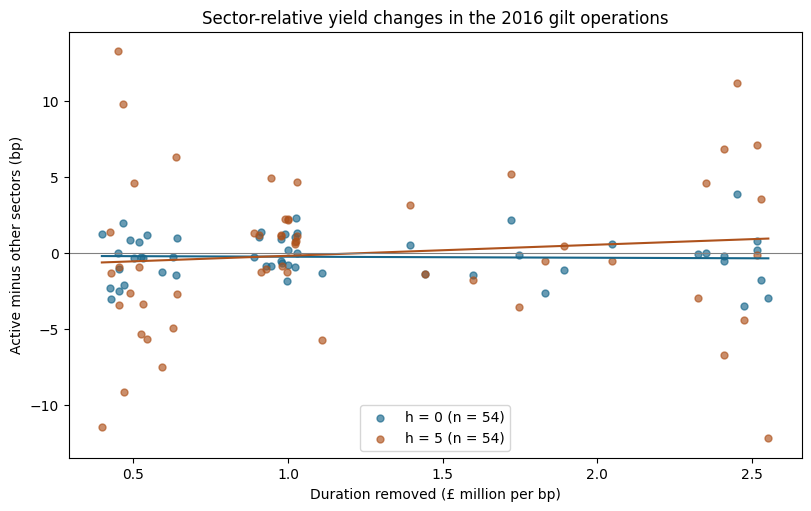

In [18]:
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
for h, colour in [(0, "#17668a"), (5, "#ae521c")]:
    points = op_h.loc[op_h["h"].eq(h), ["duration_removed", "SR"]].dropna()
    d, y = points["duration_removed"], points["SR"]
    ax.scatter(d, y, s=25, alpha=.65, color=colour, label=f"h = {h} (n = {len(d)})")
    if d.nunique() >= 2:
        limits = np.array([d.min(), d.max()])
        ax.plot(limits, np.polyval(np.polyfit(d, y, 1), limits), color=colour)
ax.axhline(0, color="0.5", lw=.8)
ax.set(xlabel="Duration removed (£ million per bp)", ylabel="Active minus other sectors (bp)",
       title="Sector-relative yield changes in the 2016 gilt operations")
ax.legend()
fig.savefig(c_out / "sector_yields_vs_duration.png", dpi=300)
plt.show()

## Step 12. Summary statistics and sample construction

**12.1 · Describe the Step 10 regression dataset.** Use each purchase with an observable $AY(0)$ once. For the eight variables in their original units, report the nonmissing count, mean, sample standard deviation, minimum, quartiles, median and maximum. Counts can differ across variables. The table is saved as `summary_statistics.csv`.

In [19]:
measures = {
    "total_allocation_nominal_mn": "Nominal allocation (£m)",
    "total_allocation_proceeds_mn": "Allocation proceeds (£m)",
    "amount_outstanding_mn": "Amount outstanding (£m nominal)",
    "relative_purchase": "Relative purchase (fraction)",
    "mod_duration_prev": "Prior modified duration (years)",
    "duration_value": "Duration value purchased (£m/bp)",
    "issue_illiquidity": "Issue-size illiquidity (negative log of £m outstanding)",
    "volatility": "Market volatility (bp)"
}
description = regression[list(measures)].rename(columns=measures).describe().T.rename(
    columns={"count": "n", "std": "sd", "50%": "median"}
)
description["n"] = description["n"].astype(int)
description.to_csv(c_out / "summary_statistics.csv", index_label="variable")
display(description.round(4))

,n,mean,sd,min,25%,median,75%,max
Nominal allocation (£m),345,136.4707,148.2278,3.9000,30.0000,75.0000,193.0000,836.4000
Allocation proceeds (£m),345,170.8586,175.1691,4.1818,41.6933,100.3253,246.5751,821.0087
Amount outstanding (£m nominal),345,26279.7494,6648.0642,4874.9990,23208.7940,27343.6800,29761.9120,37947.5880
Relative purchase (fraction),345,0.0058,0.0086,0.0001,0.0013,0.0028,0.0076,0.0929
Prior modified duration (years),345,12.9151,8.1793,2.8700,5.6500,11.0600,19.5300,32.3100
Duration value purchased (£m/bp),345,0.1817,0.2041,0.0016,0.0412,0.1143,0.2566,1.5672
Issue-size illiquidity (negative log of £m outstanding),345,-10.1288,0.3510,-10.5440,-10.3010,-10.2162,-10.0523,-8.4919
Market volatility (bp),345,4.2357,0.5372,2.9021,3.9335,4.3725,4.5710,5.1848


**12.2 · Account for every original purchase.** Apply the filters in the specified order. First require a comparison gilt, then an observable $AY(0)$, then an uncontaminated window through $h=4$. A clean row with missing $AY(4)$ survives this table. It drops out when Step 10 estimates the day-four regression. Each removed purchase receives the first reason it failed. The two outputs are `sample_construction.csv` and `excluded_purchases.csv`.

In [20]:
audit = purchases.set_index(keys)[["bond"]].copy()
for source in [
    matches.set_index(keys)["match_type"],
    panel.loc[panel["h"].eq(0)].set_index(keys)["AY"],
    panel.loc[panel["h"].eq(4)].set_index(keys)["contaminated"]
]:
    audit = audit.join(source, validate="1:1")
assert audit["match_type"].isin(["bracketed", "nearest-neighbour", "unmatched"]).all()
assert audit["contaminated"].isin([0, 1]).all()

matched = audit["match_type"].ne("unmatched")
valid_day0 = matched & audit["AY"].notna()
clean_day4 = valid_day0 & audit["contaminated"].eq(0)
assert not regression.duplicated(keys).any()
assert set(audit.index[valid_day0]) == set(regression.set_index(keys).index)

remaining = pd.Series(
    [len(audit), matched.sum(), valid_day0.sum(), clean_day4.sum()],
    index=["All purchases", "Comparison gilt found", "AY(0) available", "Uncontaminated at day 4"],
    name="remaining", dtype=int
)
construction = remaining.to_frame()
construction["removed_at_step"] = -remaining.diff().fillna(0).astype(int)

audit["Exclusion reason"] = np.select(
    [~matched, ~valid_day0, ~clean_day4],
    ["no comparison gilt", "missing abnormal yield", "contaminated event window"], default=""
)
exclusions = audit.loc[~clean_day4, ["bond", "Exclusion reason"]].reset_index()
reason_counts = exclusions["Exclusion reason"].value_counts().reindex(
    ["no comparison gilt", "missing abnormal yield", "contaminated event window"], fill_value=0
)
np.testing.assert_array_equal(reason_counts, construction["removed_at_step"].iloc[1:])
assert not exclusions.duplicated(keys).any()
assert len(exclusions) + int(clean_day4.sum()) == len(purchases)
construction.to_csv(c_out / "sample_construction.csv", index_label="stage")
exclusions.to_csv(c_out / "excluded_purchases.csv", index=False)
display(construction)

print(f"Clean at day 4: {int(clean_day4.sum())} purchases. "
      f"With a day-4 abnormal yield: {len(day4)}. "
      f"Used by the day-4 regression: {int(results.loc[results['model'].eq('Four days later'), 'n'].iloc[0])}.")

,remaining,removed_at_step
All purchases,361,0
Comparison gilt found,345,16
AY(0) available,345,0
Uncontaminated at day 4,324,21


Clean at day 4: 324 purchases. With a day-4 abnormal yield: 324. Used by the day-4 regression: 324.


## Additional validity check. Yield changes among unpurchased gilts

Step 11 gives every eligible gilt in the active sector equal weight. A fall concentrated entirely in the purchased gilts can therefore lower the sector average. To see how much of the operation-day move reached the other gilts, calculate the same spread using just the **unpurchased gilts in the active sector**. Keep the original other-sector benchmark so the two spreads can be compared directly.

Let $p_e$ be the fraction of active-sector gilts with both endpoint yields that were purchased. Let $B_e$ and $U_e$ be the average yield changes of the purchased and unpurchased active-sector gilts respectively, each measured relative to the Step 11 benchmark. With both groups represented,

$$SR_e(0)=p_e B_e+(1-p_e)U_e.$$

A negative $SR_e(0)$ alongside $U_e$ near zero can arise from moves in the bought gilts alone. A negative $U_e$ shows that the unpurchased gilts also fell relative to the benchmark. Other maturity-specific news can produce the same pattern. An operation with no usable unpurchased gilt has a missing $U_e$. The output is one row per operation in `sector_unpurchased_check.csv`.

In [21]:
day0 = sector_panel.loc[sector_panel["h"].eq(0)].copy()
day0 = day0.loc[day0["sector"].eq(day0["operation_date"].map(operation["active_sector"]))]
groups = day0.groupby(["operation_date", "purchased"])["active_change"]
counts = groups.count().unstack(fill_value=0).reindex(columns=[0, 1], fill_value=0)
means = groups.mean().unstack().reindex(columns=[0, 1])

sector_check = op_h.loc[op_h["h"].eq(0)].set_index("operation_date")[
    ["active_sector", "active_gilts", "other_gilts", "other_change_bp", "SR"]
].copy()
sector_check[["n_unpurchased", "n_purchased"]] = counts
sector_check["purchased_share"] = counts[1].div(sector_check["active_gilts"].replace(0, np.nan))
sector_check["purchased_relative_bp"] = means[1] - sector_check["other_change_bp"]
sector_check["unpurchased_relative_bp"] = means[0] - sector_check["other_change_bp"]

assert len(sector_check) == len(ops) and sector_check.index.is_unique
assert counts.sum(axis=1).eq(sector_check["active_gilts"]).all()
weights = sector_check["purchased_share"]
bought_term = (weights * sector_check["purchased_relative_bp"]).mask(counts[1].eq(0), 0)
unbought_term = ((1 - weights) * sector_check["unpurchased_relative_bp"]).mask(counts[0].eq(0), 0)
reconstructed = (bought_term + unbought_term).where(sector_check["active_gilts"].gt(0))
np.testing.assert_allclose(reconstructed, sector_check["SR"], atol=1e-10, rtol=0, equal_nan=True)
sector_check.to_csv(c_out / "sector_unpurchased_check.csv")
display(sector_check.round(3))

,active_sector,active_gilts,other_gilts,other_change_bp,SR,n_unpurchased,n_purchased,purchased_share,purchased_relative_bp,unpurchased_relative_bp
operation_date,,,,,,,,,,
2016-08-08,3–7,10,24,-3.905,-0.022,6,4,0.400,0.084,-0.092
2016-08-09,15+,16,18,-3.327,-2.958,2,14,0.875,-2.938,-3.101
2016-08-10,7–15,8,26,-5.216,2.302,2,6,0.750,2.409,1.979
2016-08-15,3–7,10,24,3.734,-2.530,4,6,0.600,-2.565,-2.476
2016-08-16,15+,16,18,4.683,-0.077,6,10,0.625,-0.034,-0.150
2016-08-17,7–15,8,26,-0.433,-0.823,2,6,0.750,-0.710,-1.164
2016-08-22,3–7,10,24,-4.293,1.969,5,5,0.500,1.895,2.042
2016-08-23,15+,16,18,-1.425,-3.537,2,14,0.875,-3.514,-3.703
2016-08-24,7–15,8,26,0.724,1.032,2,6,0.750,1.080,0.888


**Known-effect test on synthetic quotes.** The final test operation bought three of the five gilts in its sector. I reran the notebook after lowering yields by 3 bp on that date only. Each entry below is the change from the same unperturbed run, in basis points.

| Gilts receiving the temporary fall | Matched operation-day effect | Matched day-four reversal | Full sector spread | Unpurchased spread |
|---|---:|---:|---:|---:|
| Three purchased gilts | −3.0 | +3.0 | −1.8 | 0.0 |
| All five active-sector gilts | 0.0 | 0.0 | −3.0 | −3.0 |

The first row gives $-3\times 3/5=-1.8$ bp in the full sector measure even though neither unpurchased gilt was shocked. In the second row, the comparison gilts absorb the same yield shift as the purchased gilts, so the matched effect cancels. On the original files, the new `unpurchased_relative_bp` column gives the corresponding observed spread for each operation.